In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd

file_path = "/content/drive/MyDrive/cryptocast/data/processed/bitcoin_cleaned.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (4999, 8)


,Date,Price,Open,High,Low,Vol.,Change %,Vol_Log
0,2010-07-18,0.1,0.0,0.1,0.1,80.0,0.0,4.394449
1,2010-07-19,0.1,0.1,0.1,0.1,570.0,0.0,6.347389
2,2010-07-20,0.1,0.1,0.1,0.1,260.0,0.0,5.564520
3,2010-07-21,0.1,0.1,0.1,0.1,580.0,0.0,6.364751
4,2010-07-22,0.1,0.1,0.1,0.1,2160.0,0.0,7.678326


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

print(df['Date'].dtype)

datetime64[ns]


In [5]:
features = [
    'Price',
    'Open',
    'High',
    'Low',
    'Vol_Log',
    'Change %'
]

target = 'Price'

X = df[features]
y = df[target]

print("Features:", features)
print("Target:", target)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Price', 'Open', 'High', 'Low', 'Vol_Log', 'Change %']
Target: Price
X shape: (4999, 6)
y shape: (4999,)


In [6]:
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain period:")
print(train_df['Date'].min(), "to", train_df['Date'].max())

print("\nTest period:")
print(test_df['Date'].min(), "to", test_df['Date'].max())

Train shape: (3999, 8)
Test shape: (1000, 8)

Train period:
2010-07-18 00:00:00 to 2021-06-28 00:00:00

Test period:
2021-06-29 00:00:00 to 2024-03-24 00:00:00


In [7]:
X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (3999, 6)
X_test : (1000, 6)
y_train: (3999,)
y_test : (1000,)


In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nTrain feature minimums:")
print(X_train_scaled.min(axis=0))

print("\nTrain feature maximums:")
print(X_train_scaled.max(axis=0))

X_train_scaled shape: (3999, 6)
X_test_scaled shape: (1000, 6)

Train feature minimums:
[0. 0. 0. 0. 0. 0.]

Train feature maximums:
[1. 1. 1. 1. 1. 1.]


In [9]:
y_train_scaled = X_train_scaled[:, 0]
y_test_scaled = X_test_scaled[:, 0]

print("y_train_scaled shape:", y_train_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

print("\nFirst 5 train targets:")
print(y_train_scaled[:5])

print("\nFirst 5 test targets:")
print(y_test_scaled[:5])

y_train_scaled shape: (3999,)
y_test_scaled shape: (1000,)

First 5 train targets:
[0. 0. 0. 0. 0.]

First 5 test targets:
[0.56396205 0.55124896 0.52790491 0.532151   0.54677782]


In [10]:
import numpy as np

In [11]:
window_size = 60

def create_sequences(data, target, window_size, horizon):
    X_seq = []
    y_seq = []

    for i in range(window_size, len(data) - horizon + 1):
        X_seq.append(data[i-window_size:i])
        y_seq.append(target[i:i+horizon])

    return np.array(X_seq), np.array(y_seq)

In [12]:
import numpy as np

window_size = 60

def create_sequences(data, target, window_size, horizon):
    X_seq = []
    y_seq = []

    for i in range(window_size, len(data) - horizon + 1):
        X_seq.append(data[i-window_size:i])
        y_seq.append(target[i:i+horizon])

    return np.array(X_seq), np.array(y_seq)


X_train_1d, y_train_1d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    horizon=1
)

print("X_train_1d:", X_train_1d.shape)
print("y_train_1d:", y_train_1d.shape)

X_train_1d: (3939, 60, 6)
y_train_1d: (3939, 1)


In [13]:
val_index = int(len(X_train_1d) * 0.90)

X_train_final = X_train_1d[:val_index]
y_train_final = y_train_1d[:val_index]

X_val = X_train_1d[val_index:]
y_val = y_train_1d[val_index:]

print("Training:", X_train_final.shape, y_train_final.shape)
print("Validation:", X_val.shape, y_val.shape)

Training: (3545, 60, 6) (3545, 1)
Validation: (394, 60, 6) (394, 1)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense

rnn_1d = Sequential([
    Input(shape=(60, 6)),
    SimpleRNN(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(1)
])

rnn_1d.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,769 (34.25 KB)

 Trainable params: 8,769 (34.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
rnn_1d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("RNN 1-Day compiled successfully.")

RNN 1-Day compiled successfully.


In [16]:
history_rnn_1d = rnn_1d.fit(
    X_train_final,
    y_train_final,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0020 - mae: 0.0254 - val_loss: 0.0768 - val_mae: 0.2195
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0012 - mae: 0.0185 - val_loss: 0.0475 - val_mae: 0.1578
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4.4050e-04 - mae: 0.0148 - val_loss: 0.0095 - val_mae: 0.0656
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 9.9859e-05 - mae: 0.0072 - val_loss: 0.0098 - val_mae: 0.0641
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 7.9022e-05 - mae: 0.0065 - val_loss: 0.0095 - val_mae: 0.0625
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 7.2448e-05 - mae: 0.0062 - val_loss: 0.0103 - val_mae: 0.0662
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 6.7867e-05 - mae: 0.0060 - val_loss: 0.0110 - val_mae: 0.0695
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 6.6154e-05 - mae: 0.0059 - val_loss: 0.0108 - val_mae: 0.0691
Epoch 9/20
111/111 ━━━━━

In [17]:
test_context_X = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

test_context_y = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

print("Test context X shape:", test_context_X.shape)
print("Test context y shape:", test_context_y.shape)

Test context X shape: (1060, 6)
Test context y shape: (1060,)


In [18]:
X_test_1d, y_test_1d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    horizon=1
)

print("X_test_1d:", X_test_1d.shape)
print("y_test_1d:", y_test_1d.shape)

X_test_1d: (1000, 60, 6)
y_test_1d: (1000, 1)


In [19]:
y_pred_1d_scaled = rnn_1d.predict(X_test_1d)

print("Prediction shape:", y_pred_1d_scaled.shape)
print("First 5 predictions (scaled):")
print(y_pred_1d_scaled[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
Prediction shape: (1000, 1)
First 5 predictions (scaled):
[[0.4560207 ]
 [0.4779492 ]
 [0.49071366]
 [0.47564864]
 [0.47364014]]


In [20]:
y_pred_1d = scaler.inverse_transform(
    np.column_stack([
        y_pred_1d_scaled.ravel(),
        np.zeros((len(y_pred_1d_scaled), 5))
    ])
)[:, 0]

y_actual_1d = scaler.inverse_transform(
    np.column_stack([
        y_test_1d.ravel(),
        np.zeros((len(y_test_1d), 5))
    ])
)[:, 0]

print("First 5 actual prices:")
print(y_actual_1d[:5])

print("\nFirst 5 predicted prices:")
print(y_pred_1d[:5])

print("\nActual range:", y_actual_1d.min(), "to", y_actual_1d.max())
print("Predicted range:", y_pred_1d.min(), "to", y_pred_1d.max())

First 5 actual prices:
[35834.7 35026.9 33543.6 33813.4 34742.8]

First 5 predicted prices:
[28976.02091122 30369.3746583  31180.4382699  30223.19520531
 30095.5736537 ]

Actual range: 15776.2 to 73066.3
Predicted range: 15131.181687521936 to 56691.212685680395


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_rnn_1d = mean_absolute_error(
    y_actual_1d,
    y_pred_1d
)

rmse_rnn_1d = np.sqrt(
    mean_squared_error(
        y_actual_1d,
        y_pred_1d
    )
)

mape_rnn_1d = np.mean(
    np.abs(
        (y_actual_1d - y_pred_1d) / y_actual_1d
    )
) * 100

print("RNN 1-Day Metrics")
print("-----------------")
print(f"MAE : {mae_rnn_1d:.2f}")
print(f"RMSE: {rmse_rnn_1d:.2f}")
print(f"MAPE: {mape_rnn_1d:.2f}%")

RNN 1-Day Metrics
-----------------
MAE : 4842.72
RMSE: 6106.44
MAPE: 12.36%


In [22]:
rnn_1d_results = {
    'Model': 'RNN',
    'Horizon': '1-Day',
    'MAE': mae_rnn_1d,
    'RMSE': rmse_rnn_1d,
    'MAPE': mape_rnn_1d
}

print(rnn_1d_results)

{'Model': 'RNN', 'Horizon': '1-Day', 'MAE': 4842.7150456991385, 'RMSE': np.float64(6106.438926212889), 'MAPE': np.float64(12.363995368324982)}


In [23]:
X_train_3d, y_train_3d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    horizon=3
)

print("X_train_3d:", X_train_3d.shape)
print("y_train_3d:", y_train_3d.shape)

X_train_3d: (3937, 60, 6)
y_train_3d: (3937, 3)


In [24]:
val_index_3d = int(len(X_train_3d) * 0.90)

X_train_final_3d = X_train_3d[:val_index_3d]
y_train_final_3d = y_train_3d[:val_index_3d]

X_val_3d = X_train_3d[val_index_3d:]
y_val_3d = y_train_3d[val_index_3d:]

print("Training:", X_train_final_3d.shape, y_train_final_3d.shape)
print("Validation:", X_val_3d.shape, y_val_3d.shape)

Training: (3543, 60, 6) (3543, 3)
Validation: (394, 60, 6) (394, 3)


In [25]:
rnn_3d = Sequential([
    Input(shape=(60, 6)),
    SimpleRNN(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(3)
])

rnn_3d.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         4,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,899 (34.76 KB)

 Trainable params: 8,899 (34.76 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
rnn_3d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("RNN 3-Day compiled successfully.")

RNN 3-Day compiled successfully.


In [27]:
history_rnn_3d = rnn_3d.fit(
    X_train_final_3d,
    y_train_final_3d,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_3d, y_val_3d),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0013 - mae: 0.0232 - val_loss: 0.1050 - val_mae: 0.2519
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 8.5773e-04 - mae: 0.0197 - val_loss: 0.0587 - val_mae: 0.1720
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 8.1258e-04 - mae: 0.0191 - val_loss: 0.0394 - val_mae: 0.1386
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 7.7221e-04 - mae: 0.0174 - val_loss: 0.0256 - val_mae: 0.0999
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 6.7889e-04 - mae: 0.0168 - val_loss: 0.0123 - val_mae: 0.0733
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 3.7981e-04 - mae: 0.0133 - val_loss: 0.0090 - val_mae: 0.0718
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.7135e-04 - mae: 0.0109 - val_loss: 0.0364 - val_mae: 0.1068
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 3.5530e-04 - mae: 0.0121 - val_loss: 0.0067 - val_mae: 0.0528
Epoch 9/20
111/111 ━

In [28]:
X_test_3d, y_test_3d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    horizon=3
)

print("X_test_3d:", X_test_3d.shape)
print("y_test_3d:", y_test_3d.shape)

X_test_3d: (998, 60, 6)
y_test_3d: (998, 3)


In [29]:
y_pred_3d_scaled = rnn_3d.predict(X_test_3d)

print("Prediction shape:", y_pred_3d_scaled.shape)
print("First 5 predictions (scaled):")
print(y_pred_3d_scaled[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Prediction shape: (998, 3)
First 5 predictions (scaled):
[[0.63412017 0.60763246 0.49827328]
 [0.64436215 0.6287089  0.5140792 ]
 [0.6408466  0.6210136  0.5199665 ]
 [0.61475724 0.63050914 0.50958824]
 [0.6035617  0.6189253  0.48619974]]


In [30]:
predictions_3d = []
actuals_3d = []

for day in range(3):

    pred_day = scaler.inverse_transform(
        np.column_stack([
            y_pred_3d_scaled[:, day],
            np.zeros((len(y_pred_3d_scaled), 5))
        ])
    )[:, 0]

    actual_day = scaler.inverse_transform(
        np.column_stack([
            y_test_3d[:, day],
            np.zeros((len(y_test_3d), 5))
        ])
    )[:, 0]

    predictions_3d.append(pred_day)
    actuals_3d.append(actual_day)

predictions_3d = np.array(predictions_3d).T
actuals_3d = np.array(actuals_3d).T

print("Predictions shape:", predictions_3d.shape)
print("Actuals shape:", actuals_3d.shape)

print("\nFirst 5 predicted prices:")
print(predictions_3d[:5])

print("\nFirst 5 actual prices:")
print(actuals_3d[:5])

Predictions shape: (998, 3)
Actuals shape: (998, 3)

First 5 predicted prices:
[[40292.60266294 38609.55250063 31660.7830359 ]
 [40943.38660383 39948.76641092 32665.10446644]
 [40720.00628109 39459.79979544 33039.18631039]
 [39062.26682386 40063.15504265 32379.74454041]
 [38350.89322863 39327.10701323 30893.62022305]]

First 5 actual prices:
[[35834.7 35026.9 33543.6]
 [35026.9 33543.6 33813.4]
 [33543.6 33813.4 34742.8]
 [33813.4 34742.8 35298.2]
 [34742.8 35298.2 33687.8]]


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for day in range(3):

    mae_day = mean_absolute_error(
        actuals_3d[:, day],
        predictions_3d[:, day]
    )

    rmse_day = np.sqrt(
        mean_squared_error(
            actuals_3d[:, day],
            predictions_3d[:, day]
        )
    )

    mape_day = np.mean(
        np.abs(
            (actuals_3d[:, day] - predictions_3d[:, day])
            / actuals_3d[:, day]
        )
    ) * 100

    print(
        f"Day {day + 1}: "
        f"MAE = {mae_day:.2f}, "
        f"RMSE = {rmse_day:.2f}, "
        f"MAPE = {mape_day:.2f}%"
    )

Day 1: MAE = 4378.05, RMSE = 4706.46, MAPE = 13.79%
Day 2: MAE = 3628.42, RMSE = 4232.37, MAPE = 10.78%
Day 3: MAE = 3551.42, RMSE = 5103.56, MAPE = 8.74%


In [32]:
actual_flat_3d = actuals_3d.flatten()
pred_flat_3d = predictions_3d.flatten()

mae_rnn_3d = mean_absolute_error(
    actual_flat_3d,
    pred_flat_3d
)

rmse_rnn_3d = np.sqrt(
    mean_squared_error(
        actual_flat_3d,
        pred_flat_3d
    )
)

mape_rnn_3d = np.mean(
    np.abs(
        (actual_flat_3d - pred_flat_3d)
        / actual_flat_3d
    )
) * 100

print("RNN 3-Day Overall Metrics")
print("-------------------------")
print(f"MAE : {mae_rnn_3d:.2f}")
print(f"RMSE: {rmse_rnn_3d:.2f}")
print(f"MAPE: {mape_rnn_3d:.2f}%")

RNN 3-Day Overall Metrics
-------------------------
MAE : 3852.63
RMSE: 4694.32
MAPE: 11.10%


In [33]:
rnn_3d_results = {
    'Model': 'RNN',
    'Horizon': '3-Day',
    'MAE': mae_rnn_3d,
    'RMSE': rmse_rnn_3d,
    'MAPE': mape_rnn_3d
}

print(rnn_3d_results)

{'Model': 'RNN', 'Horizon': '3-Day', 'MAE': 3852.6291749082125, 'RMSE': np.float64(4694.324704901245), 'MAPE': np.float64(11.101651142697563)}


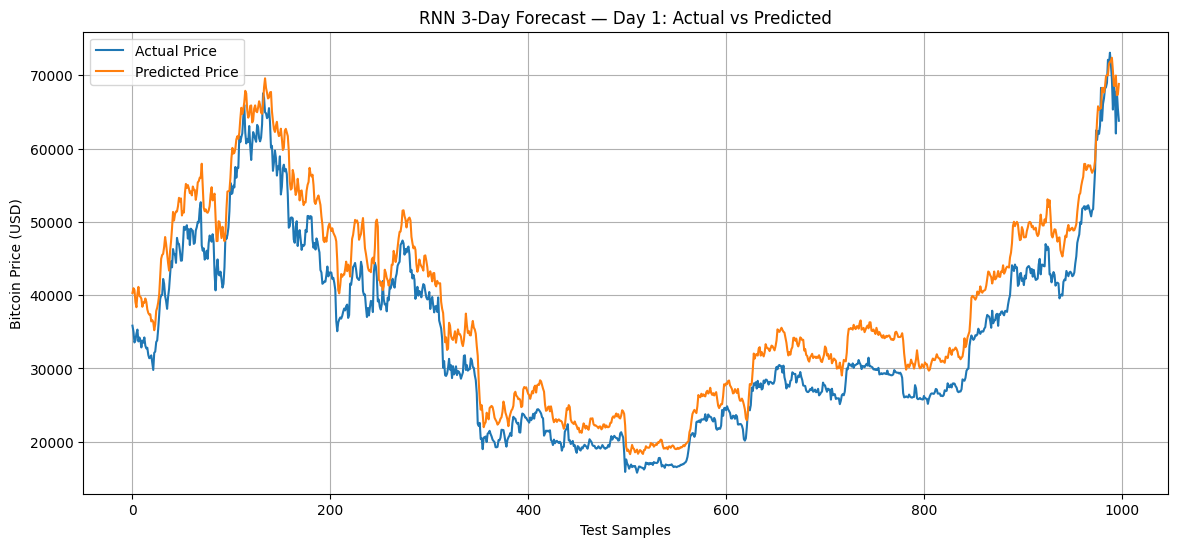

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    actuals_3d[:, 0],
    label='Actual Price'
)

plt.plot(
    predictions_3d[:, 0],
    label='Predicted Price'
)

plt.title('RNN 3-Day Forecast — Day 1: Actual vs Predicted')
plt.xlabel('Test Samples')
plt.ylabel('Bitcoin Price (USD)')
plt.legend()
plt.grid(True)

plt.show()

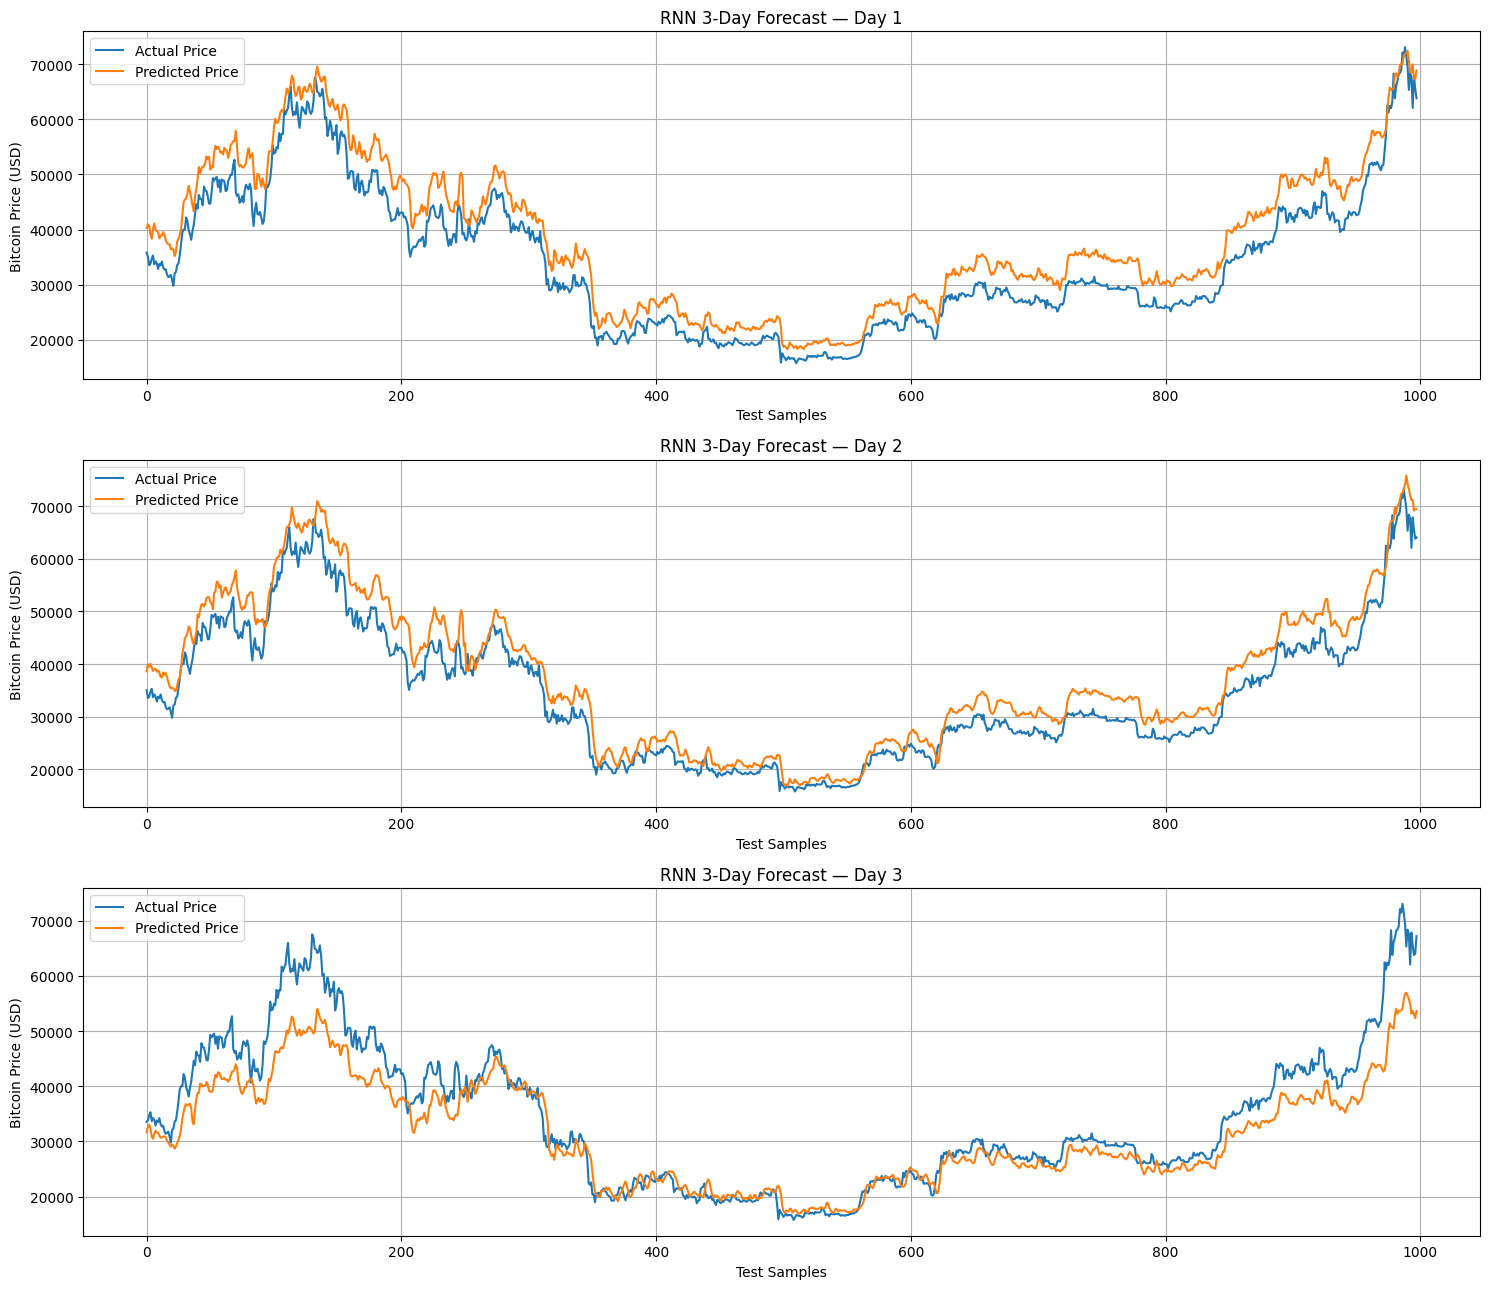

In [35]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

for day in range(3):
    axes[day].plot(
        actuals_3d[:, day],
        label='Actual Price'
    )

    axes[day].plot(
        predictions_3d[:, day],
        label='Predicted Price'
    )

    axes[day].set_title(
        f'RNN 3-Day Forecast — Day {day + 1}'
    )
    axes[day].set_xlabel('Test Samples')
    axes[day].set_ylabel('Bitcoin Price (USD)')
    axes[day].legend()
    axes[day].grid(True)

plt.tight_layout()
plt.show()

In [36]:
rnn_3d_results = {
    'Model': 'RNN',
    'Horizon': '3-Day',
    'MAE': mae_rnn_3d,
    'RMSE': rmse_rnn_3d,
    'MAPE': mape_rnn_3d
}

print(rnn_3d_results)

{'Model': 'RNN', 'Horizon': '3-Day', 'MAE': 3852.6291749082125, 'RMSE': np.float64(4694.324704901245), 'MAPE': np.float64(11.101651142697563)}


In [37]:
X_train_seq_7d, y_train_seq_7d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    7
)

print("X shape:", X_train_seq_7d.shape)
print("y shape:", y_train_seq_7d.shape)

X shape: (3933, 60, 6)
y shape: (3933, 7)


In [38]:
val_size = int(len(X_train_seq_7d) * 0.10)

X_rnn_7d_train = X_train_seq_7d[:-val_size]
y_rnn_7d_train = y_train_seq_7d[:-val_size]

X_rnn_7d_val = X_train_seq_7d[-val_size:]
y_rnn_7d_val = y_train_seq_7d[-val_size:]

print("Training:", X_rnn_7d_train.shape, y_rnn_7d_train.shape)
print("Validation:", X_rnn_7d_val.shape, y_rnn_7d_val.shape)

Training: (3540, 60, 6) (3540, 7)
Validation: (393, 60, 6) (393, 7)


In [39]:
rnn_7d = Sequential([
    Input(shape=(60, 6)),
    SimpleRNN(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(7)
])

rnn_7d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

rnn_7d.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         4,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,159 (35.78 KB)

 Trainable params: 9,159 (35.78 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
history_rnn_7d = rnn_7d.fit(
    X_rnn_7d_train,
    y_rnn_7d_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_rnn_7d_val, y_rnn_7d_val),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - loss: 0.0021 - mae: 0.0293 - val_loss: 0.0946 - val_mae: 0.2182
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0010 - mae: 0.0219 - val_loss: 0.0980 - val_mae: 0.2152
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 9.5180e-04 - mae: 0.0205 - val_loss: 0.0306 - val_mae: 0.1144
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 6.1247e-04 - mae: 0.0171 - val_loss: 0.0090 - val_mae: 0.0631
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.8232e-04 - mae: 0.0120 - val_loss: 0.0221 - val_mae: 0.0968
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 2.4895e-04 - mae: 0.0111 - val_loss: 0.0145 - val_mae: 0.0770
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 2.4204e-04 - mae: 0.0107 - val_loss: 0.0126 - val_mae: 0.0707
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 2.2058e-04 - mae: 0.0102 - val_loss: 0.0116 - val_mae: 0.0676
Epoch 9/20
111/111 ━━━━━

In [41]:
test_context_X_7d = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

test_context_y_7d = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

X_test_seq_7d, y_test_seq_7d = create_sequences(
    test_context_X_7d,
    test_context_y_7d,
    window_size,
    7
)

print("Test X shape:", X_test_seq_7d.shape)
print("Test y shape:", y_test_seq_7d.shape)

Test X shape: (994, 60, 6)
Test y shape: (994, 7)


In [42]:
predictions_7d = rnn_7d.predict(X_test_seq_7d)

print("Prediction shape:", predictions_7d.shape)
print(predictions_7d[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Prediction shape: (994, 7)
[[0.6243085  0.49339122 0.46215808 0.44566762 0.44513777 0.43432543
  0.5085913 ]
 [0.6528791  0.52948135 0.498602   0.4770733  0.4737395  0.46104833
  0.49653584]
 [0.6437318  0.51168555 0.49854347 0.47849113 0.4727215  0.462729
  0.51416945]
 [0.61596787 0.50567716 0.49718785 0.46740043 0.4683487  0.44567025
  0.49854207]
 [0.6183278  0.49492955 0.48375395 0.4314239  0.44201723 0.43589395
  0.49121377]]


In [43]:
# Inverse transform only the Price values

price_min = scaler.data_min_[0]
price_max = scaler.data_max_[0]

predictions_7d_original = (
    predictions_7d * (price_max - price_min)
) + price_min

actuals_7d_original = (
    y_test_seq_7d * (price_max - price_min)
) + price_min

print("Predicted shape:", predictions_7d_original.shape)
print("Actual shape:", actuals_7d_original.shape)

print("\nFirst 5 Predicted:")
print(predictions_7d_original[:5])

print("\nFirst 5 Actual:")
print(actuals_7d_original[:5])

Predicted shape: (994, 7)
Actual shape: (994, 7)

First 5 Predicted:
[[39669.16322165 31350.57256498 29365.99437847 28318.17739315
  28284.50995145 27597.48508029 32316.39771214]
 [41484.56151943 33643.76865149 31681.67014327 30313.71989079
  30101.88712749 29295.48003421 31550.38435297]
 [40903.33183546 32513.00920897 31677.95098834 30403.80903368
  30037.2014792  29402.27128835 32670.83847923]
 [39139.19121876 32131.23151693 31591.81392097 29699.09734631
  29759.35182223 28318.34403553 31677.86198616]
 [39289.14284925 31448.31968269 30738.21294827 27413.11990471
  28086.22824349 27697.15047903 31212.21583552]]

First 5 Actual:
[[35834.7 35026.9 33543.6 33813.4 34742.8 35298.2 33687.8]
 [35026.9 33543.6 33813.4 34742.8 35298.2 33687.8 34225.6]
 [33543.6 33813.4 34742.8 35298.2 33687.8 34225.6 33867.8]
 [33813.4 34742.8 35298.2 33687.8 34225.6 33867.8 32866.3]
 [34742.8 35298.2 33687.8 34225.6 33867.8 32866.3 33797.4]]


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rnn_7d_metrics = []

for day in range(7):
    mae = mean_absolute_error(
        actuals_7d_original[:, day],
        predictions_7d_original[:, day]
    )

    rmse = np.sqrt(mean_squared_error(
        actuals_7d_original[:, day],
        predictions_7d_original[:, day]
    ))

    mape = np.mean(
        np.abs(
            (actuals_7d_original[:, day] - predictions_7d_original[:, day])
            / actuals_7d_original[:, day]
        )
    ) * 100

    rnn_7d_metrics.append([day + 1, mae, rmse, mape])

for row in rnn_7d_metrics:
    print(
        f"Day {row[0]} → "
        f"MAE: {row[1]:.2f}, "
        f"RMSE: {row[2]:.2f}, "
        f"MAPE: {row[3]:.2f}%"
    )

Day 1 → MAE: 4543.02, RMSE: 4810.02, MAPE: 14.37%
Day 2 → MAE: 2850.82, RMSE: 3891.15, MAPE: 7.28%
Day 3 → MAE: 4610.40, RMSE: 6001.17, MAPE: 11.87%
Day 4 → MAE: 6082.92, RMSE: 7569.52, MAPE: 15.88%
Day 5 → MAE: 6620.59, RMSE: 8415.40, MAPE: 17.04%
Day 6 → MAE: 6805.91, RMSE: 8768.14, MAPE: 17.23%
Day 7 → MAE: 3694.67, RMSE: 5302.95, MAPE: 9.40%


In [45]:
actual_flat_7d = actuals_7d_original.flatten()
pred_flat_7d = predictions_7d_original.flatten()

mae_rnn_7d = mean_absolute_error(
    actual_flat_7d,
    pred_flat_7d
)

rmse_rnn_7d = np.sqrt(
    mean_squared_error(
        actual_flat_7d,
        pred_flat_7d
    )
)

mape_rnn_7d = np.mean(
    np.abs(
        (actual_flat_7d - pred_flat_7d)
        / actual_flat_7d
    )
) * 100

print(f"Overall MAE  : {mae_rnn_7d:.2f}")
print(f"Overall RMSE : {rmse_rnn_7d:.2f}")
print(f"Overall MAPE : {mape_rnn_7d:.2f}%")

Overall MAE  : 5029.76
Overall RMSE : 6626.89
Overall MAPE : 13.30%


In [46]:
rnn_7d_results = {
    'Model': 'RNN',
    'Horizon': '7-Day',
    'MAE': mae_rnn_7d,
    'RMSE': rmse_rnn_7d,
    'MAPE': mape_rnn_7d
}

print(rnn_7d_results)

{'Model': 'RNN', 'Horizon': '7-Day', 'MAE': 5029.762194668328, 'RMSE': np.float64(6626.887731439377), 'MAPE': np.float64(13.29742676911703)}


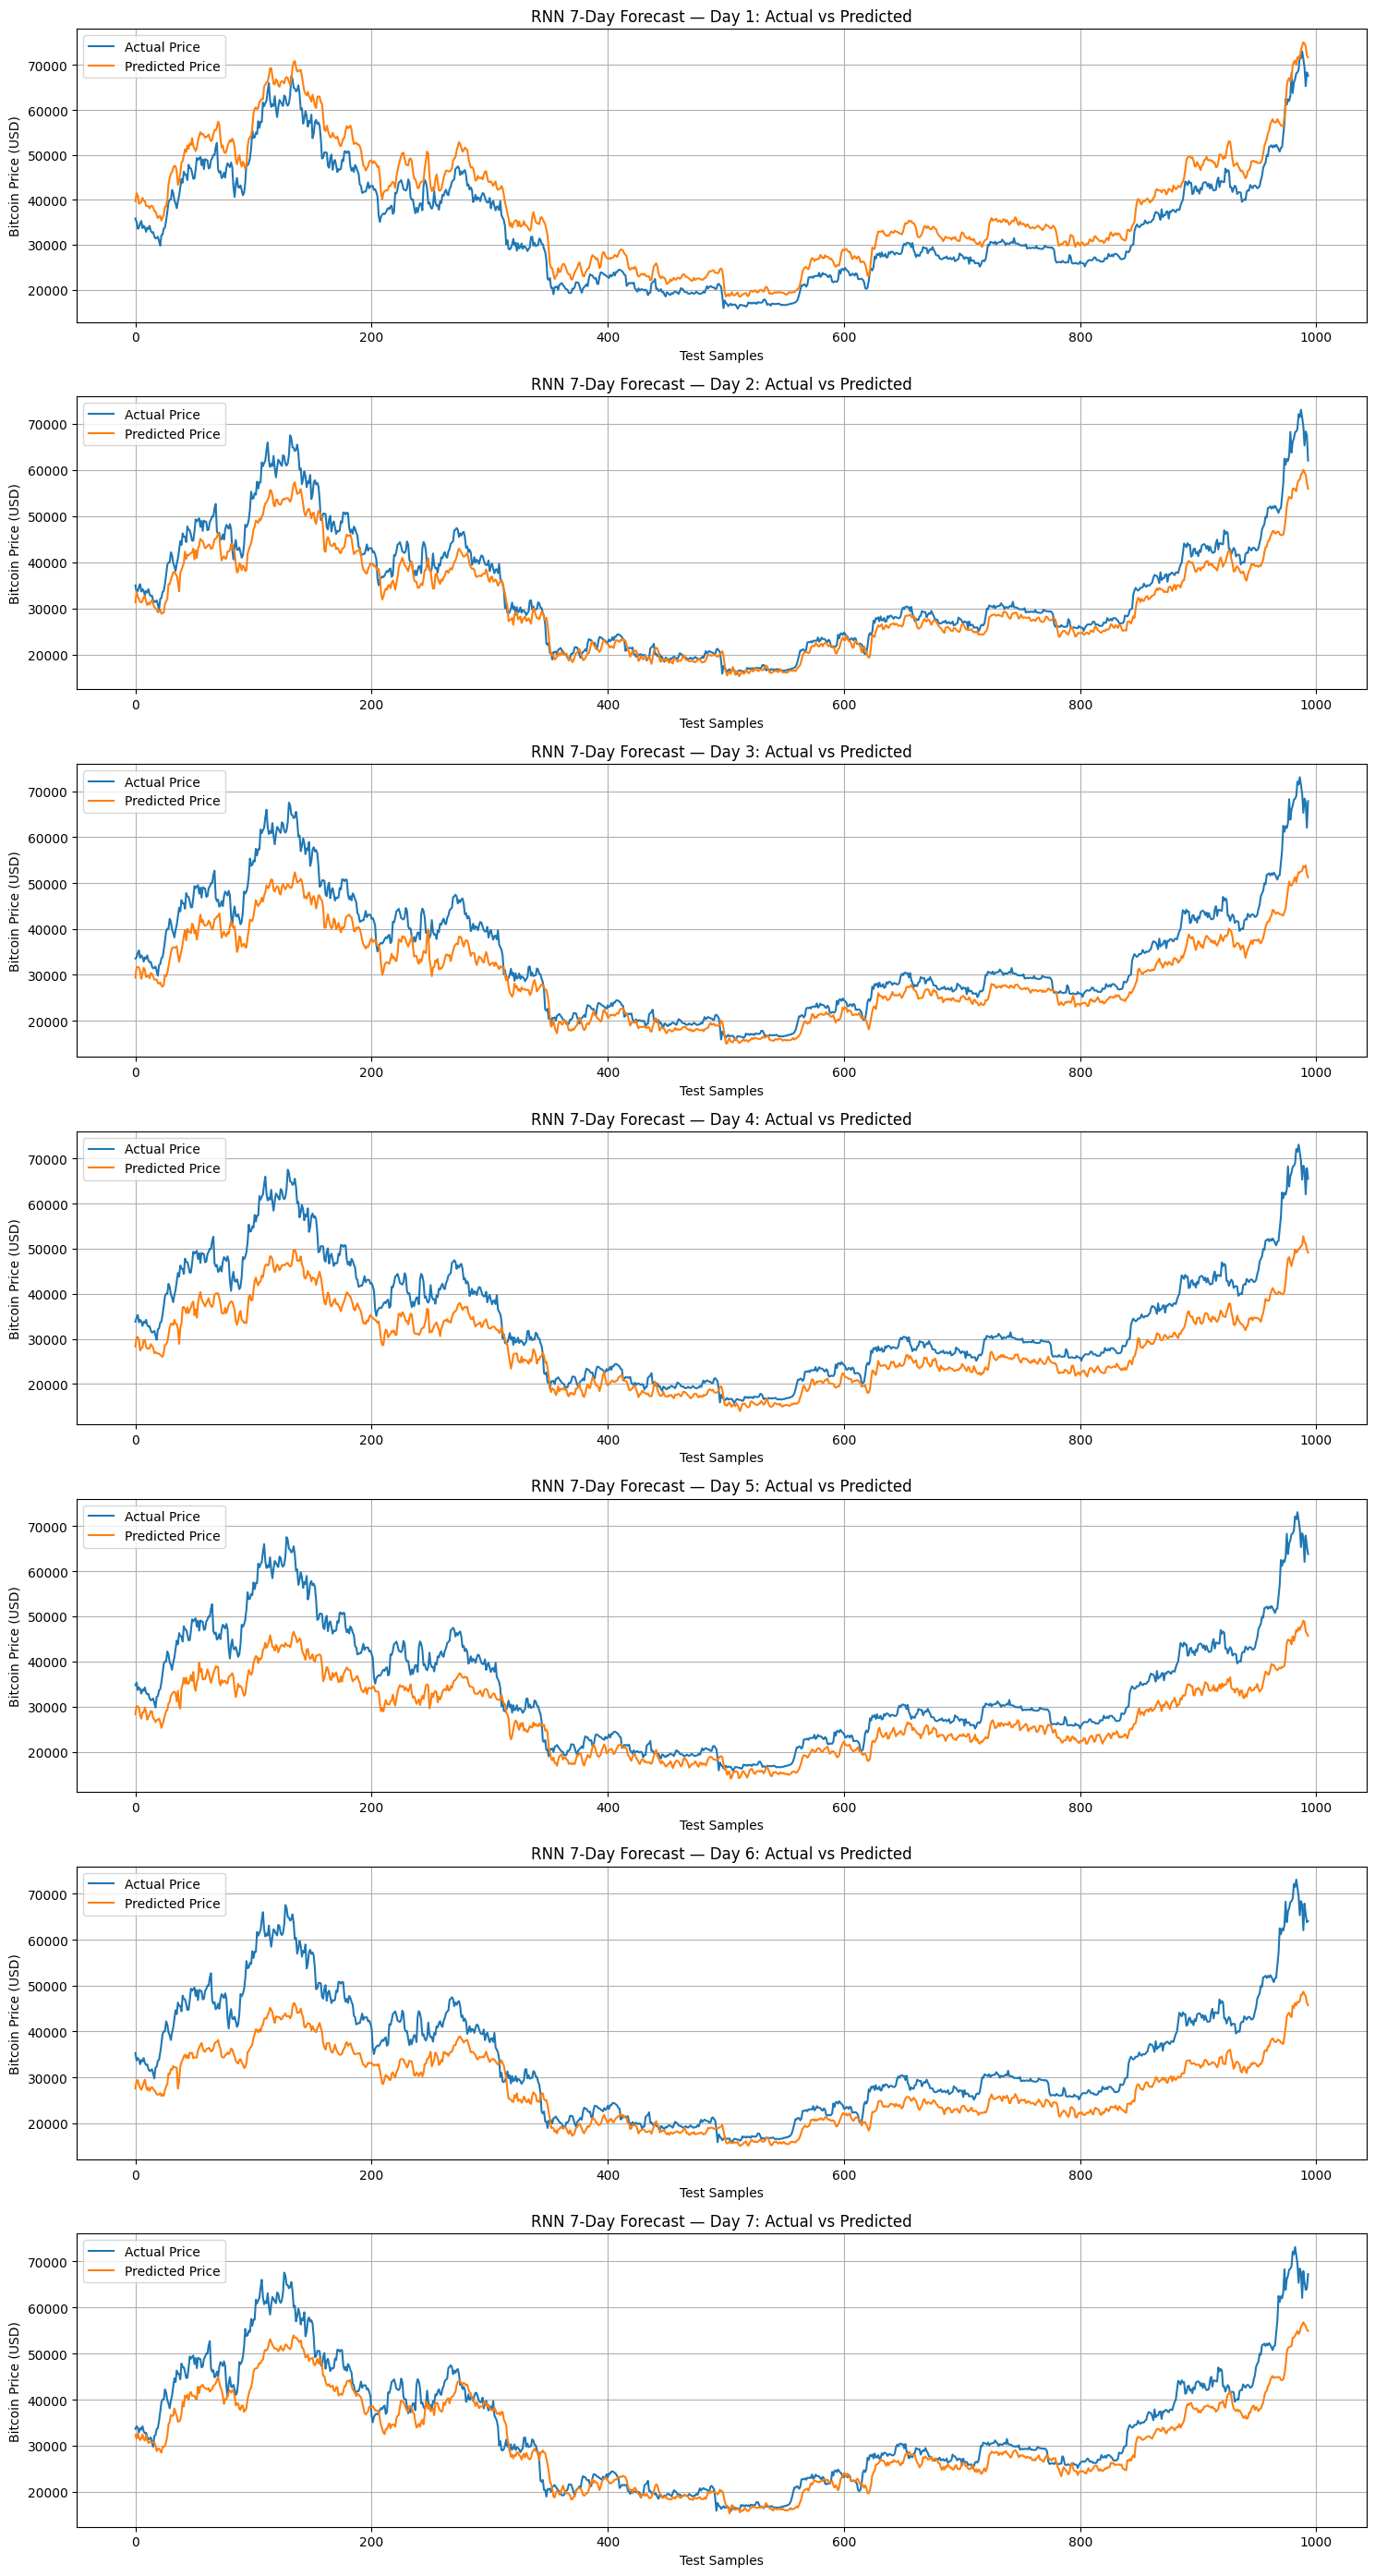

In [47]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(7, 1, figsize=(15, 28))

for day in range(7):
    axes[day].plot(
        actuals_7d_original[:, day],
        label='Actual Price'
    )
    axes[day].plot(
        predictions_7d_original[:, day],
        label='Predicted Price'
    )

    axes[day].set_title(
        f'RNN 7-Day Forecast — Day {day + 1}: Actual vs Predicted'
    )
    axes[day].set_xlabel('Test Samples')
    axes[day].set_ylabel('Bitcoin Price (USD)')
    axes[day].legend()
    axes[day].grid(True)

plt.tight_layout()
plt.show()

In [48]:
rnn_results_df = pd.DataFrame([
    rnn_1d_results,
    rnn_3d_results,
    rnn_7d_results
])

rnn_results_df

,Model,Horizon,MAE,RMSE,MAPE
0,RNN,1-Day,4842.715046,6106.438926,12.363995
1,RNN,3-Day,3852.629175,4694.324705,11.101651
2,RNN,7-Day,5029.762195,6626.887731,13.297427


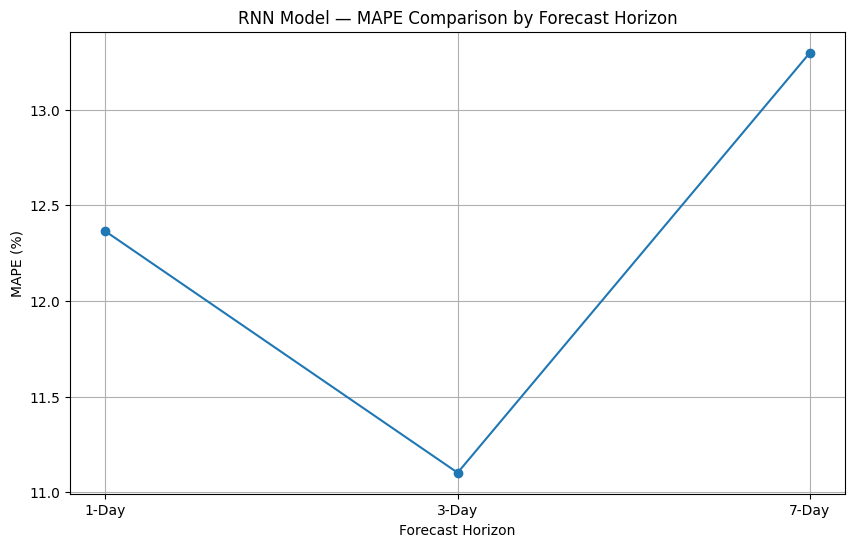

In [49]:
plt.figure(figsize=(10, 6))

plt.plot(
    rnn_results_df['Horizon'],
    rnn_results_df['MAPE'],
    marker='o'
)

plt.title('RNN Model — MAPE Comparison by Forecast Horizon')
plt.xlabel('Forecast Horizon')
plt.ylabel('MAPE (%)')
plt.grid(True)

plt.show()

In [50]:
import os

results_folder = "/content/drive/MyDrive/cryptocast/results"

os.makedirs(results_folder, exist_ok=True)

print("Results folder ready:", results_folder)

Results folder ready: /content/drive/MyDrive/cryptocast/results


In [54]:
rnn_results_path = "/content/drive/MyDrive/cryptocast/results/rnn_results.csv"

rnn_results_df.to_csv(rnn_results_path, index=False)

print("RNN results saved successfully!")
print(rnn_results_path)

RNN results saved successfully!
/content/drive/MyDrive/cryptocast/results/rnn_results.csv


In [55]:
import tensorflow as tf

print("Trained RNN models:")
for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print(name, obj.output_shape)

print("\nScaler variables:")
for name, obj in globals().copy().items():
    if "scaler" in name.lower():
        print(name, type(obj))

Trained RNN models:
rnn_1d (None, 1)
rnn_3d (None, 3)
rnn_7d (None, 7)

Scaler variables:
MinMaxScaler <class 'type'>
scaler <class 'sklearn.preprocessing._data.MinMaxScaler'>


In [56]:
import os
import joblib

model_dir = "/content/drive/MyDrive/cryptocast/streamlit/models"
os.makedirs(model_dir, exist_ok=True)

# Save RNN models
rnn_1d.save(os.path.join(model_dir, "rnn_1d.keras"))
rnn_3d.save(os.path.join(model_dir, "rnn_3d.keras"))
rnn_7d.save(os.path.join(model_dir, "rnn_7d.keras"))

# Save scaler files
for horizon in ["1d", "3d", "7d"]:
    joblib.dump(
        scaler,
        os.path.join(model_dir, f"rnn_scaler_{horizon}.pkl")
    )

print("RNN models and scaler files saved!")
print([f for f in os.listdir(model_dir) if f.startswith("rnn_")])

RNN models and scaler files saved!
['rnn_1d.keras', 'rnn_3d.keras', 'rnn_7d.keras', 'rnn_scaler_1d.pkl', 'rnn_scaler_3d.pkl', 'rnn_scaler_7d.pkl']
